# Phase I: Investigating Sentiment Classification Behavior

## Project
Sentiment Analysis under Contextual Negations and Contrastive Modifiers

## Research Objective
This project investigates how DistilBERT handles negation
expressions and contrastive sentence structures when performing
binary sentiment classification.

We focus on understanding the model's behavior rather than
simply measuring its overall classification accuracy.

## Model
distilbert/distilbert-base-uncased-finetuned-sst-2-english

## Dataset
Stanford Sentiment Treebank (SST-2) validation split (872 examples).

Only original SST-2 validation sentences are used. No synthetic
sentences are generated.

## Research Questions

1. Are SST-2 sentences containing negation markers associated with higher classification error rates?

2. Are sentences containing contrastive expressions associated with higher classification error rates?

3. How do error rates differ between sentences containing negation only,
   contrast only, both, or neither?

4. Which individual negation and contrastive markers are associated
   with more classification errors?

5. How does prediction confidence differ between correct and incorrect
   predictions across the linguistic categories?

In [1]:
import os
import random

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from datasets import load_dataset

g:\D\(Study)\M.Sc Linz\3rd semester\AI & Visualization\sentiment-negation-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Results directory
os.makedirs("results", exist_ok=True)

In [3]:
MODEL_NAME = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

print("Loading tokenizer and model...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)
model.eval()

print(f"Model loaded successfully on {device}")
print("Model labels:", model.config.id2label)

Loading tokenizer and model...


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 264.62it/s]


Model loaded successfully on cpu
Model labels: {0: 'NEGATIVE', 1: 'POSITIVE'}


In [4]:
sst2_validation = load_dataset(
    "stanfordnlp/sst2",
    split="validation"
)

In [5]:
print(len(sst2_validation))
print(sst2_validation.column_names)
print(sst2_validation.features)
print(sst2_validation[0])


pd.Series(sst2_validation["label"]).value_counts().sort_index()


872
['idx', 'sentence', 'label']
{'idx': Value('int32'), 'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'positive'])}
{'idx': 0, 'sentence': "it 's a charming and often affecting journey . ", 'label': 1}


0    428
1    444
Name: count, dtype: int64

In [6]:
for row in sst2_validation.select(range(5)):
    print("Label:", row["label"])
    print("Sentence:", row["sentence"])
    print("-" * 60)

Label: 1
Sentence: it 's a charming and often affecting journey . 
------------------------------------------------------------
Label: 0
Sentence: unflinchingly bleak and desperate 
------------------------------------------------------------
Label: 1
Sentence: allows us to hope that nolan is poised to embark a major career as a commercial yet inventive filmmaker . 
------------------------------------------------------------
Label: 1
Sentence: the acting , costumes , music , cinematography and sound are all astounding given the production 's austere locales . 
------------------------------------------------------------
Label: 0
Sentence: it 's slow -- very , very slow . 
------------------------------------------------------------


In [7]:
def get_predictions(texts, batch_size=32):

    predictions = []
    negative_probs = []
    positive_probs = []
    confidences = []

    for start in range(0, len(texts), batch_size):

        batch = texts[start:start + batch_size]

        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():
            outputs = model(**inputs)
            probabilities = torch.softmax(outputs.logits, dim=-1)

        batch_predictions = torch.argmax(probabilities, dim=1)

        for i, prediction in enumerate(batch_predictions):

            prediction_id = prediction.item()

            negative_probs.append(probabilities[i, 0].item())
            positive_probs.append(probabilities[i, 1].item())

            predictions.append(
                model.config.id2label[prediction_id]
            )

            confidences.append(
                probabilities[i, prediction_id].item()
            )

    return predictions, negative_probs, positive_probs, confidences

In [8]:
# Convert validation dataset into a DataFrame
df_sst = sst2_validation.to_pandas()

# Convert numerical labels into readable labels
df_sst["true_label"] = df_sst["label"].map({
    0: "NEGATIVE",
    1: "POSITIVE"
})

print("Running baseline predictions...")

results = get_predictions(df_sst["sentence"].tolist())

df_sst["pred_label"] = results[0]
df_sst["prob_negative"] = results[1]
df_sst["prob_positive"] = results[2]
df_sst["confidence"] = results[3]

print("Predictions completed!")

Running baseline predictions...
Predictions completed!


In [9]:
from sklearn.metrics import (accuracy_score, classification_report,confusion_matrix)

y_true = df_sst["true_label"]
y_pred = df_sst["pred_label"]

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification report:")
print(classification_report(y_true, y_pred))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=["NEGATIVE", "POSITIVE"]
))

Accuracy: 0.9106

Classification report:
              precision    recall  f1-score   support

    NEGATIVE       0.92      0.89      0.91       428
    POSITIVE       0.90      0.93      0.91       444

    accuracy                           0.91       872
   macro avg       0.91      0.91      0.91       872
weighted avg       0.91      0.91      0.91       872


Confusion matrix:
[[381  47]
 [ 31 413]]


In [10]:
df_sst.to_csv(
    "results/baseline_predictions.csv",
    index=False
)

print("Baseline results saved successfully.")

Baseline results saved successfully.


In [11]:
errors = df_sst[
    df_sst["true_label"] != df_sst["pred_label"]
].copy()

print("Total misclassified sentences:", len(errors))

false_positives = df_sst[
    (df_sst["true_label"] == "NEGATIVE") &
    (df_sst["pred_label"] == "POSITIVE")
].copy()

print("False positives:", len(false_positives))

false_negatives = df_sst[
    (df_sst["true_label"] == "POSITIVE") &
    (df_sst["pred_label"] == "NEGATIVE")
].copy()

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

columns = ["sentence", "true_label", "pred_label", "confidence"]

print("False negatives:", len(false_negatives))

display(
    false_positives[
        ["sentence", "true_label", "pred_label", "confidence"]
    ].head(5)
)

display(
    false_negatives[
        ["sentence", "true_label", "pred_label", "confidence"]
    ].head(5)
)

print("Most confident false positives:")

display(
    false_positives.sort_values(
        "confidence", ascending=False
    )[["sentence", "confidence"]].head(5)
)

print("Most confident false negatives:")

display(
    false_negatives.sort_values(
        "confidence", ascending=False
    )[["sentence", "confidence"]].head(5)
)


Total misclassified sentences: 78
False positives: 47
False negatives: 31


,sentence,true_label,pred_label,confidence
22,holden caulfield did it better .,NEGATIVE,POSITIVE,0.990752
64,"the script kicks in , and mr. hartley 's distended pace and foot-dragging rhythms follow .",NEGATIVE,POSITIVE,0.857643
92,"you wo n't like roger , but you will quickly recognize him .",NEGATIVE,POSITIVE,0.998519
95,this riveting world war ii moral suspense story deals with the shadow side of american culture : racial prejudice in its ugly and diverse forms .,NEGATIVE,POSITIVE,0.999312
107,what the director ca n't do is make either of val kilmer 's two personas interesting or worth caring about .,NEGATIVE,POSITIVE,0.941034


,sentence,true_label,pred_label,confidence
87,jaglom ... put ( s ) the audience in the privileged position of eavesdropping on his characters,POSITIVE,NEGATIVE,0.996092
93,if steven soderbergh 's ` solaris ' is a failure it is a glorious failure .,POSITIVE,NEGATIVE,0.999392
123,turns potentially forgettable formula into something strangely diverting .,POSITIVE,NEGATIVE,0.992546
142,what better message than ` love thyself ' could young women of any size receive ?,POSITIVE,NEGATIVE,0.991710
230,reign of fire looks as if it was made without much thought -- and is best watched that way .,POSITIVE,NEGATIVE,0.640311


Most confident false positives:


,sentence,confidence
791,"it 's somewhat clumsy and too lethargically paced -- but its story about a mysterious creature with psychic abilities offers a solid build-up , a terrific climax , and some nice chills along the way .",0.999791
544,"although huppert 's intensity and focus has a raw exhilaration about it , the piano teacher is anything but fun .",0.999657
183,"the lower your expectations , the more you 'll enjoy it .",0.999640
646,"the longer the movie goes , the worse it gets , but it 's actually pretty good in the first few minutes .",0.999624
519,moretti 's compelling anatomy of grief and the difficult process of adapting to loss .,0.999387


Most confident false negatives:


,sentence,confidence
93,if steven soderbergh 's ` solaris ' is a failure it is a glorious failure .,0.999392
685,no screen fantasy-adventure in recent memory has the showmanship of clones ' last 45 minutes .,0.998706
282,"while there 's something intrinsically funny about sir anthony hopkins saying ` get in the car , bitch , ' this jerry bruckheimer production has little else to offer",0.998677
87,jaglom ... put ( s ) the audience in the privileged position of eavesdropping on his characters,0.996092
266,"a coda in every sense , the pinochet case splits time between a minute-by-minute account of the british court 's extradition chess game and the regime 's talking-head survivors .",0.994838


In [12]:
negation_pattern = (
    r"\b(?:not|no|never|none|neither|nor|cannot|n't)\b"
)

contrast_pattern = (
    r"\b(?:but|however|although|though|yet|whereas|while|"
    r"nevertheless|nonetheless)\b"
)

df_sst["has_negation"] = df_sst["sentence"].str.contains(
    negation_pattern,
    case=False,
    regex=True,
    na=False
)

df_sst["has_contrast"] = df_sst["sentence"].str.contains(
    contrast_pattern,
    case=False,
    regex=True,
    na=False
)

df_sst["is_error"] = (
    df_sst["true_label"] != df_sst["pred_label"]
)

print("Negation examples:", df_sst["has_negation"].sum())
print("Contrast examples:", df_sst["has_contrast"].sum())
print("Total errors:", df_sst["is_error"].sum())

Negation examples: 172
Contrast examples: 147
Total errors: 78


In [13]:
def analyze_marker(column):

    summary = (
        df_sst.groupby(column)["is_error"]
        .agg(["count", "sum", "mean"])
        .reset_index()
    )

    summary.columns = [
        "Contains marker",
        "Total sentences",
        "Errors",
        "Error rate"
    ]

    summary["Error rate"] = (
        summary["Error rate"] * 100
    ).round(2)

    return summary


print("NEGATION ANALYSIS")
display(analyze_marker("has_negation"))

print("CONTRAST ANALYSIS")
display(analyze_marker("has_contrast"))

NEGATION ANALYSIS


,Contains marker,Total sentences,Errors,Error rate
0,False,700,53,7.57
1,True,172,25,14.53


CONTRAST ANALYSIS


,Contains marker,Total sentences,Errors,Error rate
0,False,725,58,8.00
1,True,147,20,13.61


In [14]:
interesting_errors = df_sst[
    (df_sst["is_error"]) &
    (
        df_sst["has_negation"] |
        df_sst["has_contrast"]
    )
]

display(
    interesting_errors[
        [
            "sentence",
            "true_label",
            "pred_label",
            "confidence",
            "has_negation",
            "has_contrast"
        ]
    ]
)

,sentence,true_label,pred_label,confidence,has_negation,has_contrast
92,"you wo n't like roger , but you will quickly recognize him .",NEGATIVE,POSITIVE,0.998519,True,True
107,what the director ca n't do is make either of val kilmer 's two personas interesting or worth caring about .,NEGATIVE,POSITIVE,0.941034,True,False
135,"pumpkin means to be an outrageous dark satire on fraternity life , but its ambitions far exceed the abilities of writer adam larson broder and his co-director , tony r. abrams , in their feature debut .",NEGATIVE,POSITIVE,0.920258,False,True
145,the best that can be said about the work here of scottish director ritchie ... is that he obviously does n't have his heart in it .,NEGATIVE,POSITIVE,0.856182,True,False
184,"though perry and hurley make inspiring efforts to breathe life into the disjointed , haphazard script by jay scherick and david ronn , neither the actors nor director reginald hudlin can make it more than fitfully entertaining .",NEGATIVE,POSITIVE,0.663865,True,True
213,"this time mr. burns is trying something in the martin scorsese street-realist mode , but his self-regarding sentimentality trips him up again .",NEGATIVE,POSITIVE,0.975896,False,True
248,"a full world has been presented onscreen , not some series of carefully structured plot points building to a pat resolution .",POSITIVE,NEGATIVE,0.962161,True,False
282,"while there 's something intrinsically funny about sir anthony hopkins saying ` get in the car , bitch , ' this jerry bruckheimer production has little else to offer",POSITIVE,NEGATIVE,0.998677,False,True
356,"jason x is positively anti-darwinian : nine sequels and 400 years later , the teens are none the wiser and jason still kills on auto-pilot .",NEGATIVE,POSITIVE,0.971596,True,False
358,( d ) oes n't bother being as cloying or preachy as equivalent evangelical christian movies -- maybe the filmmakers know that the likely audience will already be among the faithful .,POSITIVE,NEGATIVE,0.989791,True,False


In [15]:
conditions = [
    df_sst["has_negation"] & df_sst["has_contrast"],
    df_sst["has_negation"] & ~df_sst["has_contrast"],
    ~df_sst["has_negation"] & df_sst["has_contrast"]
]

categories = [
    "Both",
    "Negation only",
    "Contrast only"
]

df_sst["error_group"] = np.select(
    conditions,
    categories,
    default="Neither"
)

print(df_sst["error_group"].value_counts())

error_group
Neither          600
Negation only    125
Contrast only    100
Both              47
Name: count, dtype: int64


In [16]:
group_summary = (
    df_sst.groupby("error_group")
    .agg(
        total=("is_error", "count"),
        errors=("is_error", "sum"),
        mean_confidence=("confidence", "mean")
    )
    .reset_index()
)

group_summary["correct"] = (
    group_summary["total"] - group_summary["errors"]
)

group_summary["error_rate"] = (
    group_summary["errors"] / group_summary["total"] * 100
)

group_summary = group_summary.sort_values(
    "error_rate", ascending=False
)

display(group_summary.round(3))

,error_group,total,errors,mean_confidence,correct,error_rate
0,Both,47,7,0.973,40,14.894
2,Negation only,125,18,0.972,107,14.400
1,Contrast only,100,13,0.973,87,13.000
3,Neither,600,40,0.988,560,6.667


In [17]:
from scipy.stats import fisher_exact

control = group_summary[
    group_summary["error_group"] == "Neither"
].iloc[0]

statistical_results = []

for _, row in group_summary.iterrows():

    if row["error_group"] == "Neither":
        continue

    contingency_table = [
        [int(row["errors"]), int(row["correct"])],
        [int(control["errors"]), int(control["correct"])]
    ]

    odds_ratio, p_value = fisher_exact(contingency_table)

    statistical_results.append({
        "Category": row["error_group"],
        "Odds Ratio": odds_ratio,
        "P-value": p_value
    })

stats_df = pd.DataFrame(statistical_results)

# Bonferroni correction for three comparisons
stats_df["Adjusted P-value"] = (
    stats_df["P-value"] * 3
).clip(upper=1)

display(stats_df.round(4))

,Category,Odds Ratio,P-value,Adjusted P-value
0,Both,2.4500,0.0704,0.2111
1,Negation only,2.3551,0.0062,0.0187
2,Contrast only,2.0920,0.0388,0.1163


In [18]:
stats_df.to_csv(
    "results/statistical_tests.csv",
    index=False
)

In [19]:
conditions = [
    "Neither",
    "Negation only",
    "Contrast only",
    "Both"
]

selected_examples = []

for condition in conditions:

    for label in [0, 1]:

        subset = df_sst[
            (df_sst["error_group"] == condition) &
            (df_sst["label"] == label)
        ]

        examples = subset.sample(
            n=min(10, len(subset)),
            random_state=42
        )

        selected_examples.append(examples)

sst2_examples = pd.concat(
    selected_examples
).reset_index(drop=True)

display(
    sst2_examples[
        [
            "sentence",
            "true_label",
            "pred_label",
            "confidence",
            "error_group"
        ]
    ]
)

,sentence,true_label,pred_label,confidence,error_group
0,nothing is sacred in this gut-buster .,NEGATIVE,NEGATIVE,0.999069,Neither
1,"if you 've ever entertained the notion of doing what the title of this film implies , what sex with strangers actually shows may put you off the idea forever .",NEGATIVE,NEGATIVE,0.979778,Neither
2,... a hollow joke told by a cinematic gymnast having too much fun embellishing the misanthropic tale to actually engage it .,NEGATIVE,NEGATIVE,0.999669,Neither
3,"trite , banal , cliched , mostly inoffensive .",NEGATIVE,NEGATIVE,0.999792,Neither
4,"at its worst , it implodes in a series of very bad special effects .",NEGATIVE,NEGATIVE,0.999811,Neither
...,...,...,...,...,...
75,"the lion king was a roaring success when it was released eight years ago , but on imax it seems better , not just bigger .",POSITIVE,POSITIVE,0.999322,Both
76,"harrison 's flowers puts its heart in the right place , but its brains are in no particular place at all .",POSITIVE,NEGATIVE,0.993843,Both
77,"neither parker nor donovan is a typical romantic lead , but they bring a fresh , quirky charm to the formula .",POSITIVE,POSITIVE,0.999808,Both
78,"not the kind of film that will appeal to a mainstream american audience , but there is a certain charm about the film that makes it a suitable entry into the fest circuit .",POSITIVE,POSITIVE,0.999805,Both


In [20]:
sst2_examples.to_csv(
    "results/sst2_behavior_examples.csv",
    index=False
)

In [21]:
negation_pattern = (
    r"\b(not|no|never|none|neither|nor|cannot|n't)\b"
)

contrast_pattern = (
    r"\b(but|however|although|though|yet|whereas|while|"
    r"nevertheless|nonetheless)\b"
)

df_sst["negation_marker_found"] = (
    df_sst["sentence"]
    .str.lower()
    .str.extract(negation_pattern, expand=False)
)

df_sst["contrast_marker_found"] = (
    df_sst["sentence"]
    .str.lower()
    .str.extract(contrast_pattern, expand=False)
)

In [22]:
def marker_analysis(column):

    result = (
        df_sst.groupby(column, dropna=False)
        .agg(
            total=("is_error", "size"),
            errors=("is_error", "sum")
        )
        .reset_index()
    )

    result["error_rate"] = (
        result["errors"] / result["total"] * 100
    )

    return result.sort_values(
        "error_rate", ascending=False
    ).round(2)


print("NEGATION MARKERS")
display(marker_analysis("negation_marker_found"))

print("CONTRAST MARKERS")
display(marker_analysis("contrast_marker_found"))

NEGATION MARKERS


,negation_marker_found,total,errors,error_rate
4,none,4,2,50.00
1,neither,3,1,33.33
0,n't,64,12,18.75
3,no,24,4,16.67
6,not,63,5,7.94
2,never,13,1,7.69
7,NaN,700,53,7.57
5,nor,1,0,0.00


CONTRAST MARKERS


,contrast_marker_found,total,errors,error_rate
0,although,6,2,33.33
5,yet,7,1,14.29
1,but,106,14,13.21
4,while,17,2,11.76
3,though,9,1,11.11
6,NaN,725,58,8.00
2,however,2,0,0.00


In [23]:
df_sst.to_csv(
    "results/sst2_full_analysis.csv",
    index=False
)

group_summary.to_csv(
    "results/error_group_summary.csv",
    index=False
)

marker_analysis("negation_marker_found").to_csv(
    "results/negation_marker_analysis.csv",
    index=False
)

marker_analysis("contrast_marker_found").to_csv(
    "results/contrast_marker_analysis.csv",
    index=False
)

print("Analysis files saved.")

Analysis files saved.


In [24]:
FIGURES_DIR = "results/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

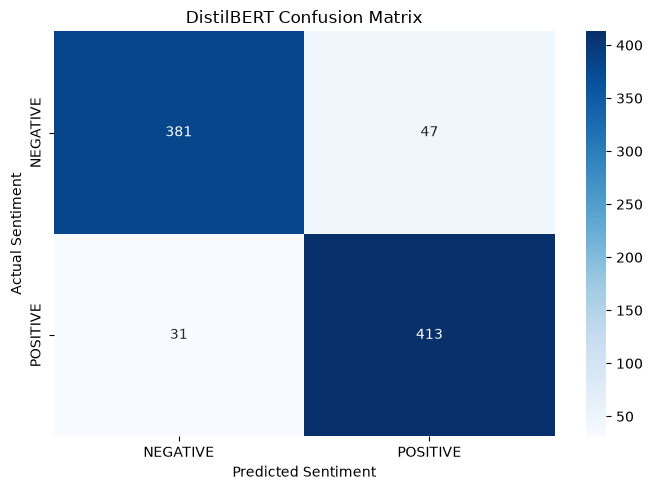

In [25]:
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(7, 5))

cm = confusion_matrix(
    df_sst["true_label"],
    df_sst["pred_label"],
    labels=["NEGATIVE", "POSITIVE"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NEGATIVE", "POSITIVE"],
    yticklabels=["NEGATIVE", "POSITIVE"]
)

plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()

plt.savefig(f"{FIGURES_DIR}/confusion_matrix.png", dpi=300)
plt.show()

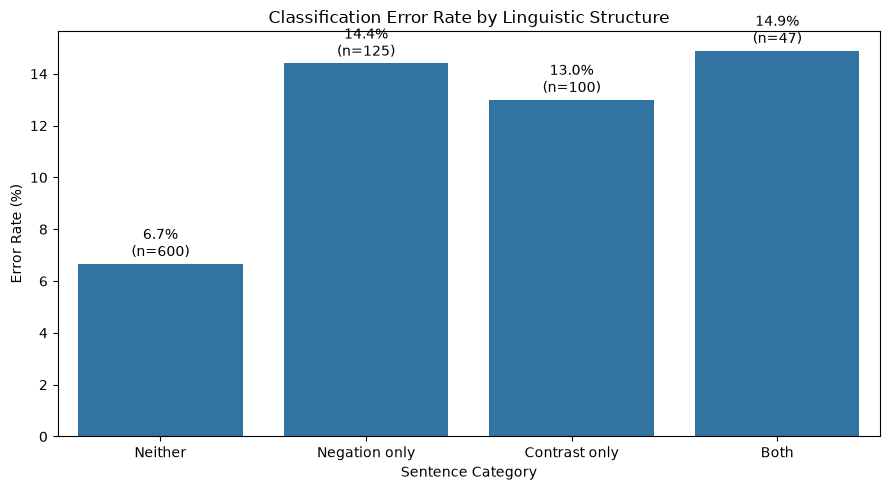

In [26]:
plt.figure(figsize=(9, 5))

order = [
    "Neither",
    "Negation only",
    "Contrast only",
    "Both"
]

plot_data = group_summary.set_index(
    "error_group"
).loc[order].reset_index()

ax = sns.barplot(
    data=plot_data,
    x="error_group",
    y="error_rate"
)

for i, row in plot_data.iterrows():
    ax.text(
        i,
        row["error_rate"] + 0.3,
        f'{row["error_rate"]:.1f}%\n(n={row["total"]})',
        ha="center"
    )

plt.title("Classification Error Rate by Linguistic Structure")
plt.xlabel("Sentence Category")
plt.ylabel("Error Rate (%)")
plt.tight_layout()

plt.savefig(f"{FIGURES_DIR}/error_rates_by_condition.png", dpi=300)
plt.show()

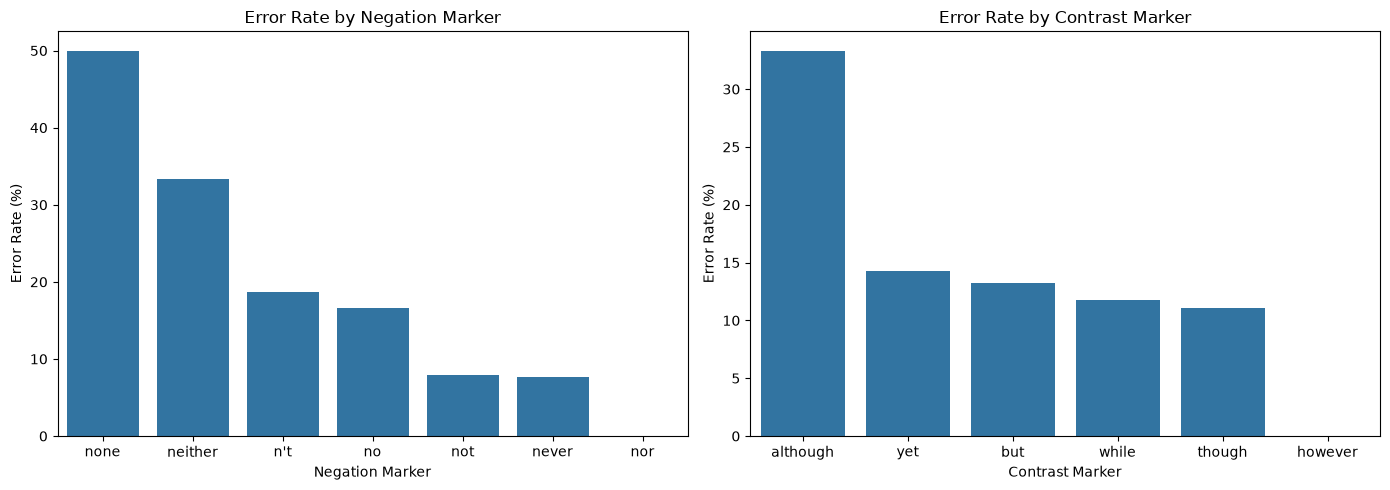

In [27]:
negation_data = marker_analysis(
    "negation_marker_found"
).dropna(subset=["negation_marker_found"])

contrast_data = marker_analysis(
    "contrast_marker_found"
).dropna(subset=["contrast_marker_found"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=negation_data,
    x="negation_marker_found",
    y="error_rate",
    ax=axes[0]
)

axes[0].set_title("Error Rate by Negation Marker")
axes[0].set_xlabel("Negation Marker")
axes[0].set_ylabel("Error Rate (%)")

sns.barplot(
    data=contrast_data,
    x="contrast_marker_found",
    y="error_rate",
    ax=axes[1]
)

axes[1].set_title("Error Rate by Contrast Marker")
axes[1].set_xlabel("Contrast Marker")
axes[1].set_ylabel("Error Rate (%)")

plt.tight_layout()

plt.savefig(f"{FIGURES_DIR}/marker_error_rates.png", dpi=300)
plt.show()

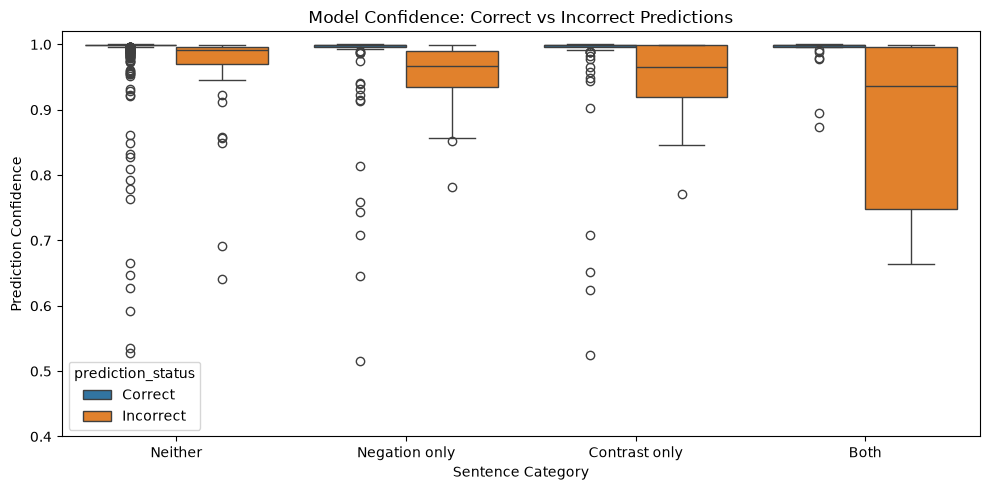

In [28]:
df_sst["prediction_status"] = df_sst["is_error"].map({
    False: "Correct",
    True: "Incorrect"
})

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_sst,
    x="error_group",
    y="confidence",
    hue="prediction_status",
    order=order
)

plt.title("Model Confidence: Correct vs Incorrect Predictions")
plt.xlabel("Sentence Category")
plt.ylabel("Prediction Confidence")
plt.ylim(0.4, 1.02)
plt.tight_layout()

plt.savefig(f"{FIGURES_DIR}/confidence_comparison.png", dpi=300)
plt.show()

In [29]:
df_sst.to_csv(
    "results/sst2_full_analysis.csv",
    index=False
)

group_summary.to_csv(
    "results/error_group_summary.csv",
    index=False
)

print("All analytical results saved.")
print("Figures directory:", FIGURES_DIR)

All analytical results saved.
Figures directory: results/figures


In [31]:
from pathlib import Path

results_dir = Path("results")
figures_dir = results_dir / "figures"

print("RESULT FILES")
for file in sorted(results_dir.glob("*.csv")):
    print(f"✓ {file.name}")

print("\nVISUALIZATION FILES")
for file in sorted(figures_dir.glob("*.png")):
    print(f"✓ {file.name}")

RESULT FILES
✓ baseline_predictions.csv
✓ contrast_marker_analysis.csv
✓ error_group_summary.csv
✓ negation_marker_analysis.csv
✓ sst2_behavior_examples.csv
✓ sst2_full_analysis.csv
✓ statistical_tests.csv

VISUALIZATION FILES
✓ confidence_comparison.png
✓ confusion_matrix.png
✓ error_rates_by_condition.png
✓ marker_error_rates.png
